# 1. Scaricare i dati da argopy

In [44]:
from datetime import datetime
from argopy import DataFetcher, ArgoIndex
from storage.cache_manager import MemoryManager
from processing.conversions import convert_mmol
from processing.netcdf_formatter import convert_argo_to_standard
%load_ext autoreload
%autoreload 2

def download_profiles(start, end, mode="standard"):
    region = [-5, 36, 30, 46, 0, 2000, start, end]
    params = ['DOXY']
    idx = ArgoIndex(index_file="bgc-s")
    idx.query.box(region[:4] + region[6:])
    data_idx = idx.to_dataframe()
    df = DataFetcher(mode=mode, ds='bgc', params=params, indexfs=idx).region(region)
    df.load()
    data = df.data
    profiles = data.argo.point2profile()
    return profiles

def save_profiles(p, directory):
    p = convert_mmol(p)
    p = convert_argo_to_standard(p)
    mm = MemoryManager(dir_name=directory)
    mm.save_profiles(p)
    return mm


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Not downloading redundant profiles

In [3]:
"""
import os
existing_wmo = []
for (root,dirs,files) in os.walk('data'):
    for file in files:
        existing_wmo.append(file)

box_wmo = [path.split("/")[-1] for path in data_idx["file"]]
wmo_to_download = [wmo for wmo in box_wmo if wmo not in existing_wmo]

wmos = [file_name.split("_")[0][2:] for file_name in wmo_to_download]
cycles = [file_name.split("_")[1].split(".")[0][:3] for file_name in wmo_to_download]
"""


'\nimport os\nexisting_wmo = []\nfor (root,dirs,files) in os.walk(\'data\'):\n    for file in files:\n        existing_wmo.append(file)\n\nbox_wmo = [path.split("/")[-1] for path in data_idx["file"]]\nwmo_to_download = [wmo for wmo in box_wmo if wmo not in existing_wmo]\n\nwmos = [file_name.split("_")[0][2:] for file_name in wmo_to_download]\ncycles = [file_name.split("_")[1].split(".")[0][:3] for file_name in wmo_to_download]\n'

# 2. Preprocessing dei dati in input per il modello

## Test standard formatting

In [4]:
# from processing.netcdf_formatter import convert_argo_to_standard
# profiles_formatted = convert_argo_to_standard(profiles)

## Opening as xarray

In [5]:
# print(list(profiles.keys()))
import xarray as xr
# data = xr.open_dataset("example_data/6901774/SR6901774_113.nc")
#.isel(N_PROF=0)

In [2]:


# profiles = standard.load_profiles()


In [7]:
# print(profiles)

## Check differences in argopy vs carolina

In [45]:
profiles = download_profiles("2020-07-01", "2020-08-01")
sm = save_profiles(profiles, directory="data_standard")

Saving 84 profiles...
data/data_standard/6903262/SD6903262_095.nc SAVED.
data/data_standard/6903781/SD6903781_002.nc SAVED.
data/data_standard/6903263/SD6903263_094.nc SAVED.
data/data_standard/6903246/SD6903246_124.nc SAVED.
data/data_standard/6902904/SD6902904_154.nc SAVED.
data/data_standard/6903247/SD6903247_143.nc SAVED.
data/data_standard/6901775/SD6901775_155.nc SAVED.
data/data_standard/6903266/SD6903266_237.nc SAVED.
data/data_standard/6903237/SD6903237_169.nc SAVED.
data/data_standard/6901774/SD6901774_111.nc SAVED.
data/data_standard/6903250/SD6903250_140.nc SAVED.
data/data_standard/6903781/SD6903781_003.nc SAVED.
data/data_standard/6903262/SD6903262_096.nc SAVED.
data/data_standard/6903263/SD6903263_095.nc SAVED.
data/data_standard/6903246/SD6903246_125.nc SAVED.
data/data_standard/6903247/SD6903247_144.nc SAVED.
data/data_standard/6903266/SD6903266_238.nc SAVED.
data/data_standard/6902904/SD6902904_155.nc SAVED.
data/data_standard/6903237/SD6903237_170.nc SAVED.
data/data

In [46]:
e_profiles = download_profiles("2020-06-01", "2020-08-01", "expert")
em = save_profiles(e_profiles, directory="data_expert")

Saving 459 profiles...
data/data_expert/6903262/SD6903262_089.nc SAVED.
data/data_expert/6903263/SD6903263_088.nc SAVED.
data/data_expert/6903288/S6903288_057.nc SAVED.
data/data_expert/6903249/SD6903249_136.nc SAVED.
data/data_expert/7900562/SD7900562_058.nc SAVED.
data/data_expert/6903249/SD6903249_137.nc SAVED.
data/data_expert/6903765/SD6903765_045.nc SAVED.
data/data_expert/6903246/SD6903246_118.nc SAVED.
data/data_expert/6902902/S6902902_163.nc SAVED.
data/data_expert/6903247/SD6903247_137.nc SAVED.
data/data_expert/6902969/SD6902969_099.nc SAVED.
data/data_expert/6903247/SD6903247_138.nc SAVED.
data/data_expert/6902899/S6902899_060.nc SAVED.
data/data_expert/6902803/SD6902803_231.nc SAVED.
data/data_expert/6902804/SD6902804_233.nc SAVED.
data/data_expert/6902898/S6902898_219.nc SAVED.
data/data_expert/6903288/S6903288_058.nc SAVED.
data/data_expert/6902870/SD6902870_096.nc SAVED.
data/data_expert/6902873/SD6902873_104.nc SAVED.
data/data_expert/6902875/SD6902875_096.nc SAVED.
da

In [49]:
from graphics.plotter import plot_similar_comparison
from storage.cache_manager import MemoryManager

standard_memory = MemoryManager(dir_name="data_standard")
superfloat_memory = MemoryManager(dir_name="data_example")
expert_memory = MemoryManager(dir_name="data_expert")

In [50]:
expert_paths = expert_memory.get_profiles_paths()
print(len(expert_paths))
standard_paths = standard_memory.get_profiles_paths()
print(len(standard_paths))
superfloat_paths = superfloat_memory.get_profiles_paths()
print(len(superfloat_paths))


420
80
16631


In [96]:
import numpy as np
import pandas as pd

def get_profile_name(p):
    import os
    return os.path.basename(p).replace("SD", "")

expert_profile_names = set([get_profile_name(p) for p in expert_paths])
standard_profile_names = set([get_profile_name(p) for p in standard_paths])
superfloat_profile_names = set([get_profile_name(p) for p in superfloat_paths])

common_paths = expert_profile_names & standard_profile_names & superfloat_profile_names
print(len(common_paths))

25


Comparisons for 6903246_128.nc


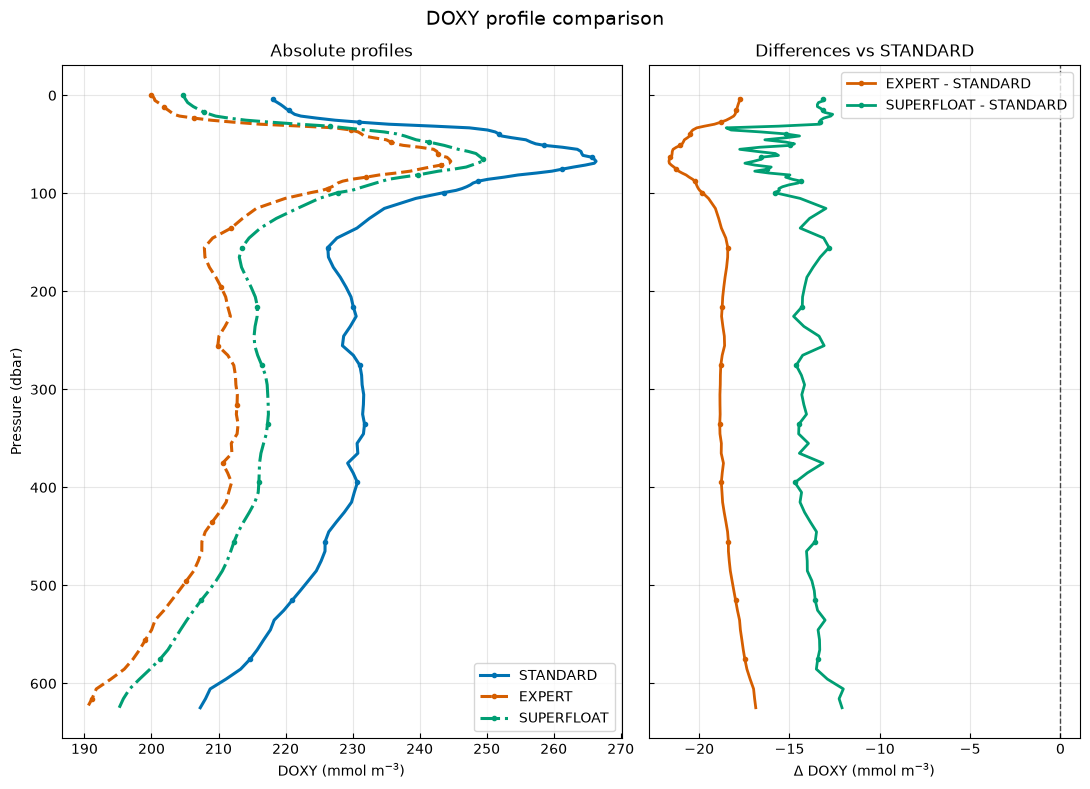

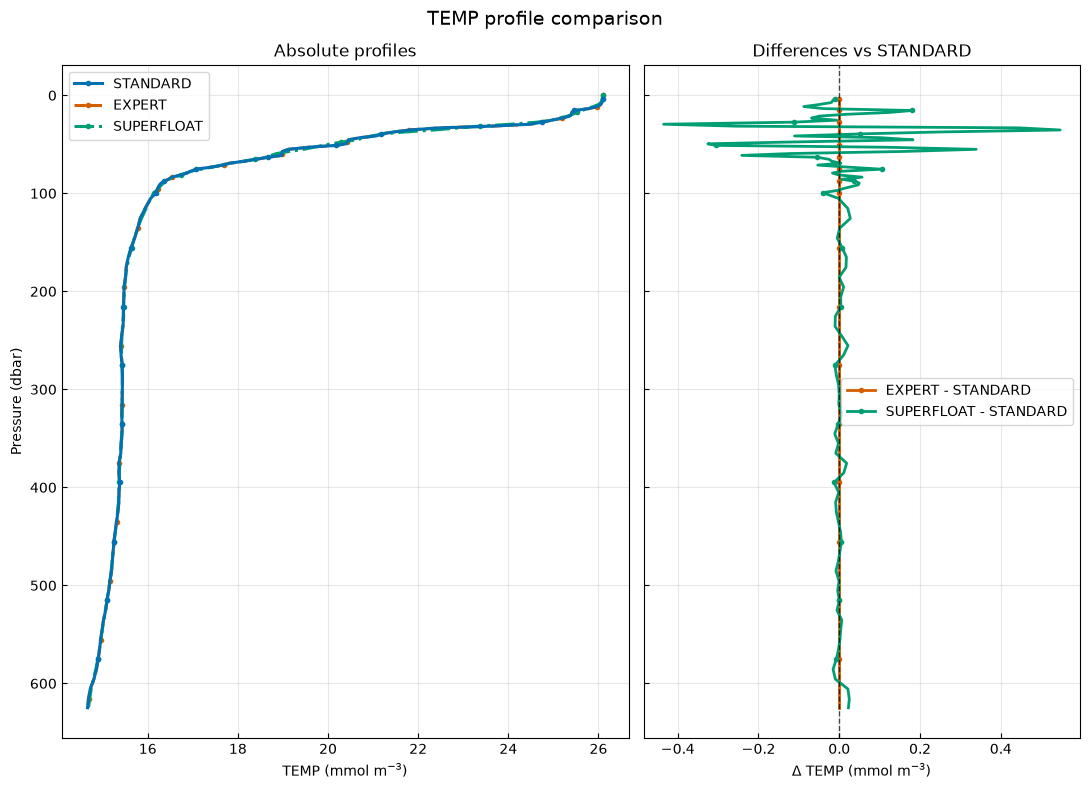

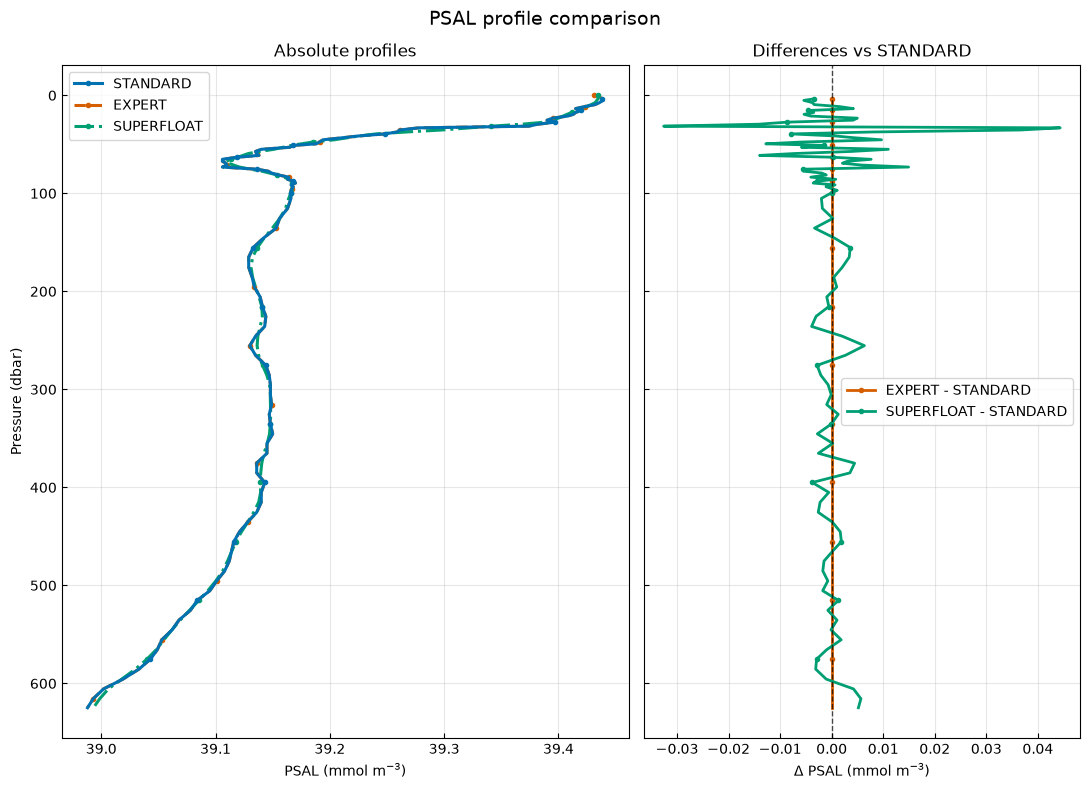

In [95]:
profile_name = common_paths.pop().replace(".nc", '')

print("Comparisons for", profile_name)
name_profiles = {"STANDARD": standard_memory.load_profile(profile_name),
                 "EXPERT": expert_memory.load_profile(profile_name),#}
                 "SUPERFLOAT": superfloat_memory.load_profile(profile_name)}


plot_similar_comparison(name_profiles=name_profiles, attr="DOXY", title=f"{profile_name}")
plot_similar_comparison(name_profiles=name_profiles, attr="TEMP", title=f"{profile_name}")
plot_similar_comparison(name_profiles=name_profiles, attr="PSAL", title=f"{profile_name}")


In [14]:

differences = []
for path in common_paths:
    ds_std = standard_memory.load_profile(path)
    ds_exp = expert_memory.load_profile(path)

    if ds_std is None or ds_exp is None:
        continue

    # Esempio su DOXY o TEMP (assicurati che le dimensioni combacino)
    if 'DOXY' in ds_std and 'DOXY' in ds_exp:
        diff = np.nanmean(np.abs(ds_exp['DOXY'] - ds_std['DOXY']))
        differences.append({'path': path, 'mean_diff_doxy': diff})

df_diff = pd.DataFrame(differences)
print(df_diff.describe())  # Vedi subito se ci sono variazioni significative

/var/folders/6b/kdhvc02d60s28_j0gc62tsz80000gn/T/ipykernel_44716/3671622827.py:16: RuntimeWarning: Mean of empty slice
  diff = np.nanmean(np.abs(ds_exp['DOXY'] - ds_std['DOXY']))


       mean_diff_doxy
count       99.000000
mean        17.507455
std         11.475604
min          3.682145
25%          8.137464
50%         15.501328
75%         23.130952
max         52.204271
